In [1]:
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [4]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
def applyCut(inputDataframe, cut):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def calc_hist(vals, bins=10, weights=None, density=True):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [10]:
def getEff(pythiaFile, pythiaCuts):
    observables2 = ['pt','m','q2','rg','zg','mg','w','reject']
    observabless2 = ['pts','ms','q2s','rgs','zgs','mgs','ws','rejects']
    inputFiles = ['/vast/palmer/home.grace/ys668/output/run12/all0818_2.root']
    treeName = ["MatchedTree"]
    df = applyCut(addNewBranches(getData(observables2+observabless2, inputFiles[0], treeName[0])),pythiaCuts)
    match_miss, _ = np.histogram(df[ob], range=(range_low,range_high), bins=bins, weights=df['w'])
    match, _ = np.histogram(df[(df.ms>1) & (df.pts>15)][ob], range=(range_low,range_high), bins=bins, weights=df[(df.ms>1) & (df.pts>15)]['w'])
    return match/(1e-50+match_miss)

In [8]:
def addNewBranches(inputDataframe):
    df_temp = inputDataframe
    df_temp.eval('dm=m-mg',inplace=True)
    df_temp.eval('dm_frac=dm/m',inplace=True)
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df_temp[df_temp.a<0.000001]['a'] = 0
    df_temp[['loga']] = np.log10(df_temp[['a']].replace(0, np.nan))
    df_temp.mask(df_temp.isna(),-4.1,inplace=True)
    return df_temp

In [9]:
def getFull(effFile, pythiaCuts, ofCsvPath, ofCuts, it, nom=False, filelist=None):

    if filelist is None:
        filelist = np.arange(1,21)
        
    df2s = []
    for i in filelist:
        
        df_temp = pd.read_csv(path+ofCsvPath+'jet_noweight.csv', low_memory=False)
        df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
        df_temp[df_temp.a<0.000001]['a'] = 0
        df_temp[['loga']] = np.log10(df_temp[['a']].replace(0, np.nan))
        df_temp.mask(df_temp.isna(),-4.1,inplace=True)
        df_temp['weight'] = pd.read_csv(path+ofCsvPath+'it'+str(it)+'_seed'+str(i)+'.csv', low_memory=False)
        df2s.append(applyCut(df_temp, ofCuts))
    y2s = []
    for i in range(0, len(filelist)):
        y2s.append(np.histogram(df2s[i][ob], range=(range_low,range_high), bins=bins, weights=df2s[i]['weight'], density=True)[0])
    y2 = np.average(y2s, axis=0)
    y2_err = np.std(y2s, axis=0)
    
    y = y2/(1e-50+getEff(effFile, pythiaCuts))
    norm = sum(y)
    y = y/norm
    if (nom==False):
        err_seed=0
        err_it=0
    else:
        err_seed = y2_err/(np.sqrt(len(filelist))*norm) # use standard error

    return y/sum(y), err_seed/sum(y)

In [6]:
def getErrUnf(y_nom,y_hw,y_p8,err_seed):
    err4 = np.array(y_nom/sum(y_nom))-np.array(y_hw/sum(y_hw))
    err5 = np.array(y_nom/sum(y_nom))-np.array(y_p8/sum(y_p8))
    err6 = err_seed/sum(y_nom)
    err_unf=[]
    for i in range(0,len(err4)):
        err_unf.append( np.sqrt( (max(abs(err4[i]),abs(err5[i])))**2 + (err6[i])**2 ) )
    return np.array(err_unf)

In [5]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [11]:
path = '/gpfs/gibbs/project/caines/ys668/run12/csvs/'
nom_path = 'newemb_6d_largebatch_092723/'
hw_path = 'herwig_newemb_7dreweight_6dunfold_largebatch_092723/'
py8_path = 'pythia8_newemb_7dreweight_6dunfold_largebatch_092723/'

In [12]:
it_mean = 15

In [13]:
ob = 'loga'
range_low = -4.5
range_high = -0.
bins = 9
binwidth = (range_high - range_low)/bins

In [14]:
x = np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)

In [15]:
cut = '20<pt<30 and 0.4<zg<0.5 and 0<rg<0.1'
y_nom_1, err_seed_1 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_1, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_1, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_1 = getErrUnf(y_nom_1,y_hw_1,y_p8_1,err_seed_1)

In [16]:
cut = '20<pt<30 and 0.4<zg<0.5 and 0.15<rg<0.25'
y_nom_2, err_seed_2 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_2, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_2, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_2 = getErrUnf(y_nom_2,y_hw_2,y_p8_2,err_seed_2)

In [17]:
cut = '20<pt<30 and 0.1<zg<0.2 and 0.15<rg<0.25'
y_nom_3, err_seed_3 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_3, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_3, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_3 = getErrUnf(y_nom_3,y_hw_3,y_p8_3,err_seed_3)

In [18]:
cut = '20<pt<30 and 0.1<zg<0.2 and 0.3<rg<0.4'
y_nom_4, err_seed_4 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    nom_path, cut, it_mean, nom=True)
y_hw_4, err_seed_hw = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    hw_path, cut, it_mean, nom=True)
y_p8_4, err_seed_p8 = getFull('$HOME/output/run12/all0818_2.root',
    'rg!=-1 and reject<=0 and rejects<=0 and '+cut,
    py8_path, cut, it_mean, nom=True)
err_unf_4 = getErrUnf(y_nom_4,y_hw_4,y_p8_4,err_seed_4)

(-0.07527688678451837, 1.7)

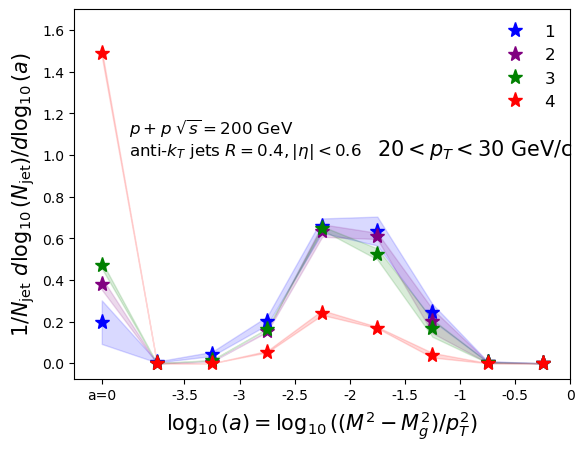

In [19]:
fig, ax = plt.subplots()
line1, = plt.plot(x, 2*y_nom_1/sum(y_nom_1), label='1', color='b', marker='*', markersize=11, ls='none')
linea = plt.fill_between(x, 2*(y_nom_1/sum(y_nom_1)-err_unf_1), 2*(y_nom_1/sum(y_nom_1)+err_unf_1), color='b', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line2, = plt.plot(x, 2*y_nom_2/sum(y_nom_2), label='2', color='purple', marker='*', markersize=11, ls='none')
lineb = plt.fill_between(x, 2*(y_nom_2/sum(y_nom_2)-err_unf_2), 2*(y_nom_2/sum(y_nom_2)+err_unf_2), color='purple', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line3, = plt.plot(x, 2*y_nom_3/sum(y_nom_3), label='3', color='g', marker='*', markersize=11, ls='none')
linec = plt.fill_between(x, 2*(y_nom_3/sum(y_nom_3)-err_unf_3), 2*(y_nom_3/sum(y_nom_3)+err_unf_3), color='g', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
line4, = plt.plot(x, 2*y_nom_4/sum(y_nom_4), label='4', color='r', marker='*', markersize=11, ls='none')
lined = plt.fill_between(x, 2*(y_nom_4/sum(y_nom_4)-err_unf_4), 2*(y_nom_4/sum(y_nom_4)+err_unf_4), color='r', alpha=0.15, label='Unfolding sys. only\n(seed+prior)')
plt.text(-1.75, 1,'$20<p_T<30$ GeV/c', fontsize=15)
#plt.text(-3.9, 1.0, '6D multifolded\n15 iterations\nFake rate from old emb.\nefficiency from new emb.')
#plt.text(-3.9, 0.5,'Truth-level:\n$0<R_g<0.4$\nweak decays off\n$\pi^0$ decays on')
plt.text(-4, 1., '$p+p$ $\sqrt{s}=200$ GeV\nanti-$k_T$ jets $R=0.4, |\eta|<0.6$', fontsize=12)
plt.xlabel('log(a)')
plt.xticks([-4.25,-3.5,-3,-2.5,-2,-1.5,-1,-.5,0],['a=0','-3.5','-3','-2.5','-2','-1.5','-1','-0.5','0'])
plt.xlim(-4.5,0.)
l1 = ax.legend(handles=[line1,line2,line3,line4], frameon=False, loc='upper right', fontsize=12)
plt.xlabel('$\log_{10}(a) = \log_{10}((M^2-M_g^2)/p_T^2)$', fontsize=15)
plt.ylabel(r'$1/N_{\mathrm{jet}}$ $d\log_{10}(N_{\mathrm{jet}})/d\log_{10}(a)$', fontsize=15)
plt.ylim(top=1.7)